# 江南跨年 13 天旅遊花費分析

**目標**：把手排的 Excel 行程表（`上海.xlsx`）整理成乾淨的資料，回答三個問題：

1. 這趟旅行**每人大約要花多少錢**？
2. 錢主要花在**哪一類**（機票、住宿、交通、門票、餐飲）？
3. 哪幾天**花最多**？行程表裡有沒有**資料不一致**的地方？

> 資料來源：作者自己規劃的行程表。金額前面有「台」的是新台幣，其餘是人民幣；多數金額寫成「價錢/幾人」。

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

# 中文字型（Windows 可改成 'Microsoft JhengHei'）
plt.rcParams['font.family'] = ['Noto Sans CJK TC', 'Microsoft JhengHei', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False

RMB_TO_TWD = 4.4      # ⚠️ 假設匯率：出發前請到台灣銀行網站更新「現金賣出」匯率
PEOPLE = 2            # 行程表的金額多寫「/2人」，以 2 人計算
FILE = 'data/上海.xlsx'

## 1. 讀取資料

「總攬」工作表的欄位：A 日期、B 時間、C 行程、H 交通、K 價錢、L 飯店。日期只寫在每天第一列，所以要**往下填滿（forward fill）**。

In [2]:
raw = pd.read_excel(FILE, sheet_name='總攬', header=0, usecols='A:C,H,K,L')
raw.columns = ['日期', '時間', '行程', '交通', '價錢', '飯店']
raw['日期'] = raw['日期'].ffill()
raw = raw[raw['日期'].notna()]
raw['日期'] = raw['日期'].astype(str).str.extract(r'(\d{2}/\d{2})')[0]
priced = raw[raw['價錢'].notna()].copy()
print('總列數：', len(raw), '／有寫價錢的列：', len(priced))
priced.head(10)

總列數： 129 ／有寫價錢的列： 44


,日期,時間,行程,交通,價錢,飯店
2,12/24,NaN,台北 ➔ 上海｜聖誕夜遊外灘,桃園 (TPE) ➔ 上海浦東 (PVG),沒有是人民幣,NaN
3,12/24,NaN,NaN,中華航空 CI 501,台20000/1人,NaN
7,12/24,13:10:00,寄存行李,NaN,兩晚1700/2人,麗呈璀際酒店
9,12/24,19:30 - 21:30,洛克·外灘源平安夜狂歡/圓明園路步行街,腳,門票80/2人,NaN
10,12/24,22:00:00,散步返回飯店休息,NaN,平均一晚850/2人,麗呈璀際酒店
14,12/25,10:20 - 13:00,搭車至豫園 / 城隍廟/也可在房休息,搭乘 地鐵 10 號線（往基隆路/航中路方向,10/2人,NaN
16,12/25,13:30 - 17:00,開市客(上海浦東店),網約車,60/2人,NaN
17,12/25,18:00:00,外灘海關亮燈,網約車,60/2人,NaN
18,12/25,19:30 - 21:30,洛克·外灘源/圓明園路步行街/太累可以不走去/換吃羊肉串,網約車,60/2人,NaN
19,12/25,19:30 - 21:30,靈活調動/可去很久以前羊肉串,網約車,60/2人,NaN


## 2. 清理價錢欄位

價錢的寫法很多種，要先寫規則把它們統一成「**每人花多少新台幣**」：

| 原始寫法 | 意思 | 處理方式 |
|---|---|---|
| `台20000/1人` | 新台幣，每人 | 直接用 |
| `60/2人` | 人民幣，2 人合計 | ÷ 2 × 匯率 |
| `兩晚1700/2人`、`900/2晚/2人` | 住宿總價 | 記下晚數，算每人總額 |
| `平均一晚850/2人` | 由總價算出的平均 | **不重複計入**，只拿來檢查 |
| `480/1艘船` | 一艘船 2 人坐 | ÷ 2 |
| `一份30` | 一份小吃 | 假設每人一份 |
| `門票300/2人(200/2人)` | 括號是備案價格 | 取第一個價格 |

In [3]:
CN_NUM = {'一': 1, '兩': 2, '二': 2, '三': 3}

def parse_price(text):
    s = str(text).strip()
    if s.startswith('平均'):
        return None                      # 平均值是重複資訊，不計入
    m = re.search(r'(\d+)', s)
    if not m:
        return None
    amount = int(m.group(1))
    currency = 'TWD' if s.startswith('台') else 'RMB'
    nights = None
    n = re.search(r'([一兩二三\d])晚', s)
    if n:
        nights = CN_NUM.get(n.group(1)) or int(n.group(1))
    if '/1人' in s:
        per_person = amount
    elif '艘船' in s or '/2人' in s:
        per_person = amount / 2
    else:                                # 例如「一份30」：每人一份
        per_person = amount
    return {'幣別': currency, '原始金額': amount, '晚數': nights, '每人金額': per_person}

def category(row):
    p, trip, traffic = str(row['價錢']), str(row['行程']), str(row['交通'])
    if '晚' in p:                        return '住宿'
    if p.startswith('台') or '航空' in traffic: return '機票'
    if re.search(r'門票|滑雪|艘船', p):   return '門票體驗'
    if re.search(r'一份|小吃|奶茶|鍋貼', p + trip): return '餐飲'
    if traffic not in ('nan', '腳'):     return '交通'
    return '其他'

parsed = priced['價錢'].apply(parse_price)
items = priced[parsed.notna()].copy()
items = pd.concat([items.reset_index(drop=True),
                   pd.DataFrame(list(parsed.dropna())).reset_index(drop=True)], axis=1)
items['類別'] = items.apply(category, axis=1)
items['每人台幣'] = items.apply(
    lambda r: r['每人金額'] if r['幣別'] == 'TWD' else r['每人金額'] * RMB_TO_TWD, axis=1).round()
items[['日期', '行程', '價錢', '類別', '每人金額', '幣別', '每人台幣']]

,日期,行程,價錢,類別,每人金額,幣別,每人台幣
0,12/24,NaN,台20000/1人,機票,20000.0,TWD,20000.0
1,12/24,寄存行李,兩晚1700/2人,住宿,850.0,RMB,3740.0
2,12/24,洛克·外灘源平安夜狂歡/圓明園路步行街,門票80/2人,門票體驗,40.0,RMB,176.0
3,12/25,搭車至豫園 / 城隍廟/也可在房休息,10/2人,交通,5.0,RMB,22.0
4,12/25,開市客(上海浦東店),60/2人,交通,30.0,RMB,132.0
5,12/25,外灘海關亮燈,60/2人,交通,30.0,RMB,132.0
6,12/25,洛克·外灘源/圓明園路步行街/太累可以不走去/換吃羊肉串,60/2人,交通,30.0,RMB,132.0
7,12/25,靈活調動/可去很久以前羊肉串,60/2人,交通,30.0,RMB,132.0
8,12/25,五角場下沉式廣場 欣賞巨型彩蛋 3D 燈光秀,60/2人,交通,30.0,RMB,132.0
9,12/26,飯店出門，搭乘網約車直達上海千古情景區,60/2人,交通,30.0,RMB,132.0


## 3. 餐飲：從每日美食筆記估算

總攬表大部分沒寫餐費，但每天的分頁有「人均 RMB 150–250」這類筆記。這裡抓出所有**有範圍的人均價格**，加總成每人的餐飲預估（最低～最高）。只有一個數字或寫「300+」的備案不計入。

In [4]:
food_rows = []
xl = pd.ExcelFile(FILE)
for sheet in xl.sheet_names[1:]:
    df = pd.read_excel(FILE, sheet_name=sheet, header=None)
    for v in df.values.flatten():
        s = str(v)
        m = re.search(r'人均[^\d]*(\d+)\s*[–-]\s*(\d+)', s)
        if m:
            food_rows.append({'分頁': sheet, '最低': int(m.group(1)), '最高': int(m.group(2)), '原文': s[:40]})
food = pd.DataFrame(food_rows)
food_min = food['最低'].sum() * RMB_TO_TWD
food_max = food['最高'].sum() * RMB_TO_TWD
print(f'共 {len(food)} 餐有人均價格；每人餐飲預估 NT${food_min:,.0f} ～ NT${food_max:,.0f}')
food

共 14 餐有人均價格；每人餐飲預估 NT$4,378 ～ NT$6,644


,分頁,最低,最高,原文
0,12 24,150,250,預估價位： 人均 RMB 150–250。
1,12 24,90,130,單點： 人均約 RMB 90 - 130。
2,12 25,60,100,預估價位： 人均 RMB 60–100。
3,12 25,110,140,預估價位： 人均 RMB 110–140。
4,1226,30,50,預估價位： 人均 RMB 30–50。
5,1227,25,35,人均 RMB 25–35。
6,1228,150,220,人均 RMB 150–220
7,1229-1231,30,45,人均 RMB 30–45
8,1229-1231,100,150,人均 RMB 100–150
9,0101,25,40,預估價位： 人均 RMB 25–40


## 4. 結果：每人總花費與類別占比

In [5]:
by_cat = items.groupby('類別')['每人台幣'].sum()
food_mid = (food_min + food_max) / 2
by_cat['餐飲'] = by_cat.get('餐飲', 0) + food_mid
by_cat = by_cat.sort_values()
total = by_cat.sum()
summary = pd.DataFrame({'每人台幣': by_cat.round(), '占比': (by_cat / total * 100).round(1).astype(str) + '%'})
print(f'每人總花費約 NT${total:,.0f}（餐飲取預估中間值；匯率 {RMB_TO_TWD}）')
summary.sort_values('每人台幣', ascending=False)

每人總花費約 NT$63,197（餐飲取預估中間值；匯率 4.4）


,每人台幣,占比
類別,,
住宿,26180.0,41.4%
機票,20000.0,31.6%
門票體驗,8008.0,12.7%
餐飲,6083.0,9.6%
交通,2926.0,4.6%


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


...

findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


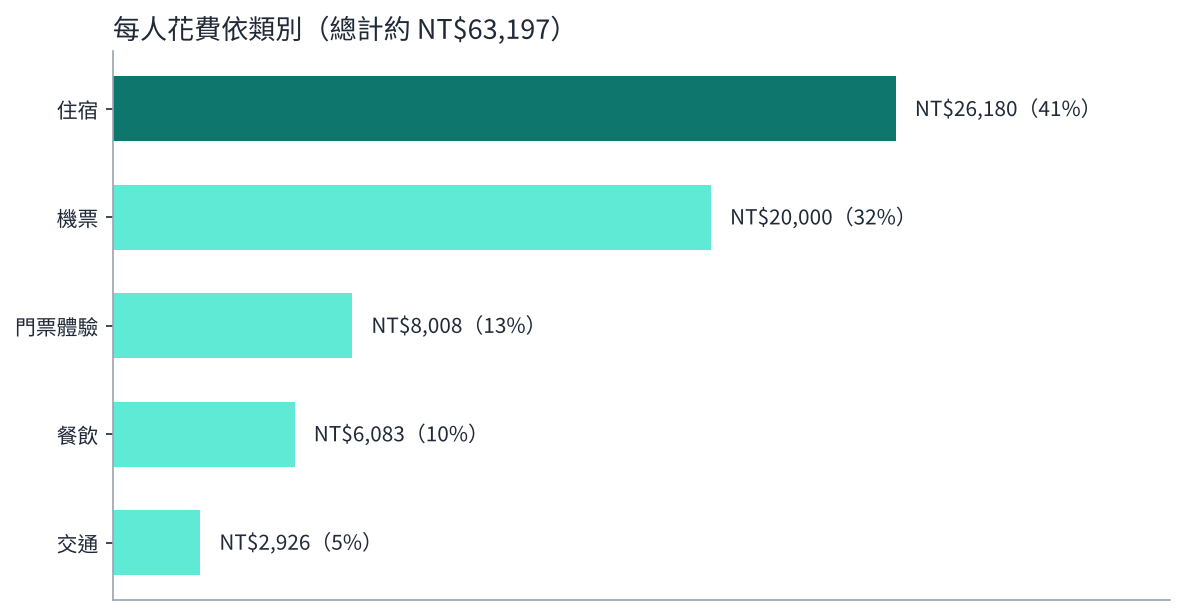

In [6]:
ACCENT, MUTED, INK = '#0f766e', '#9ca3af', '#1f2937'
fig, ax = plt.subplots(figsize=(8, 4.2), dpi=150)
colors = [ACCENT if c == by_cat.idxmax() else '#5eead4' for c in by_cat.index]
bars = ax.barh(by_cat.index, by_cat.values, color=colors, height=0.6)
for b, v in zip(bars, by_cat.values):
    ax.text(v + total * 0.01, b.get_y() + b.get_height() / 2,
            f'NT${v:,.0f}（{v / total:.0%}）', va='center', fontsize=10, color=INK)
ax.set_title(f'每人花費依類別（總計約 NT${total:,.0f}）', loc='left', fontsize=13, color=INK)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color(MUTED)
ax.tick_params(colors=INK)
ax.set_xlim(0, by_cat.max() * 1.35)
ax.xaxis.set_visible(False)
plt.tight_layout(); plt.savefig('outputs/1_類別占比.png'); plt.show()

## 5. 哪幾天花最多？（不含機票與餐飲預估）

findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


...

findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


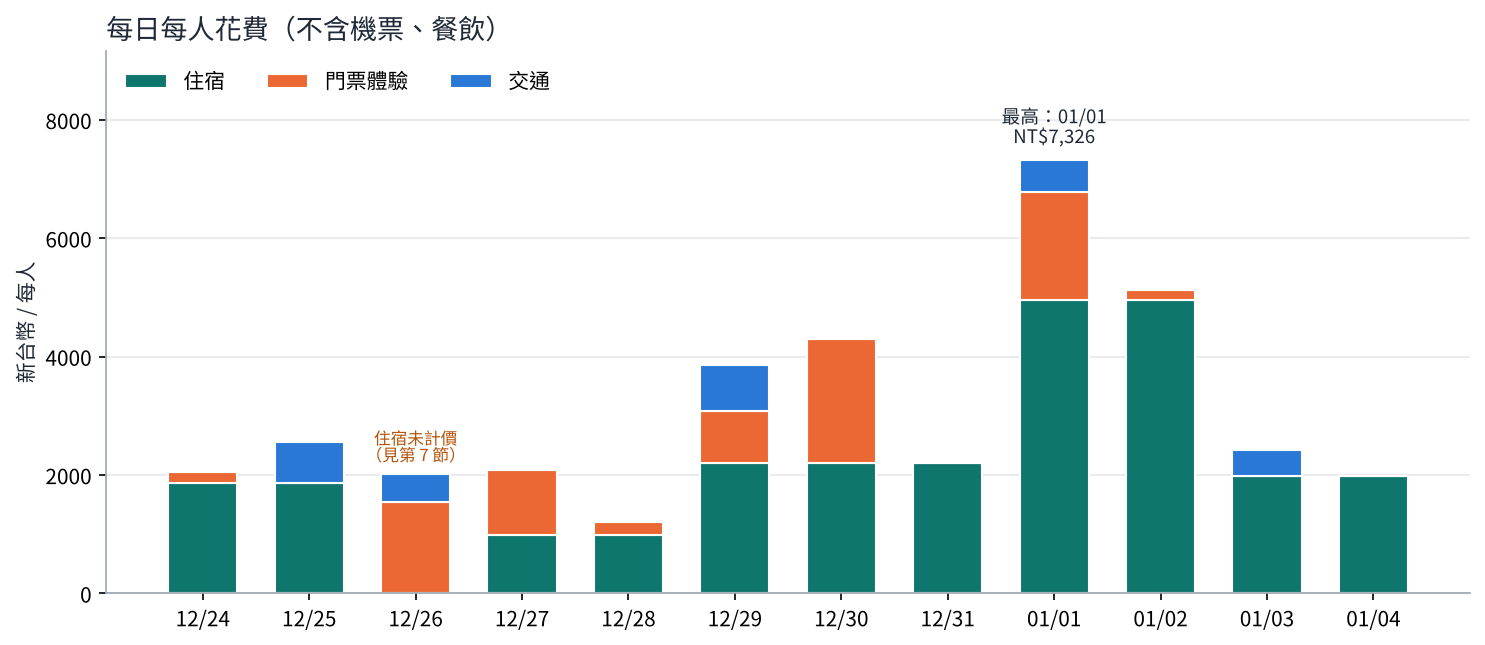

類別,交通,住宿,門票體驗,合計
日期,,,,
12/24,0.0,1870.0,176.0,2046.0
12/25,682.0,1870.0,0.0,2552.0
12/26,484.0,0.0,1540.0,2024.0
12/27,0.0,990.0,1100.0,2090.0
12/28,0.0,990.0,220.0,1210.0
12/29,770.0,2200.0,880.0,3850.0
12/30,0.0,2200.0,2090.0,4290.0
12/31,0.0,2200.0,0.0,2200.0
01/01,550.0,4950.0,1826.0,7326.0


In [7]:
daily = items[~items['類別'].isin(['機票', '餐飲'])].copy()
# 住宿總價依晚數平均攤到入住的每一晚
rows = []
for _, r in daily.iterrows():
    if r['類別'] == '住宿' and r['晚數']:
        start = pd.to_datetime('2026/' + r['日期'] if r['日期'] >= '12' else '2027/' + r['日期'])
        for k in range(int(r['晚數'])):
            d = (start + pd.Timedelta(days=k)).strftime('%m/%d')
            rows.append({'日期': d, '類別': '住宿', '每人台幣': r['每人台幣'] / r['晚數']})
    else:
        rows.append({'日期': r['日期'], '類別': r['類別'], '每人台幣': r['每人台幣']})
d = pd.DataFrame(rows)
order = sorted(d['日期'].unique(), key=lambda x: ('1' if x.startswith('12') else '2') + x)
pivot = d.pivot_table(index='日期', columns='類別', values='每人台幣', aggfunc='sum').reindex(order).fillna(0)
cats = [c for c in ['住宿', '門票體驗', '交通', '餐飲'] if c in pivot.columns]
pal = {'住宿': '#0f766e', '門票體驗': '#eb6834', '交通': '#2a78d6', '餐飲': '#eda100'}

fig, ax = plt.subplots(figsize=(10, 4.4), dpi=150)
bottom = pd.Series(0, index=pivot.index)
for c in cats:
    ax.bar(pivot.index, pivot[c], bottom=bottom, label=c, color=pal[c], width=0.65, edgecolor='white', linewidth=1)
    bottom += pivot[c]
top = bottom.idxmax()
ax.annotate(f'最高：{top}\nNT${bottom.max():,.0f}', xy=(top, bottom.max()), xytext=(0, 8),
            textcoords='offset points', ha='center', fontsize=9, color=INK)
ax.set_title('每日每人花費（不含機票、餐飲）', loc='left', fontsize=13, color=INK)
if '12/26' in pivot.index and pivot.loc['12/26', '住宿'] == 0:
    ax.annotate('住宿未計價\n（見第 7 節）', xy=('12/26', bottom['12/26']), xytext=(0, 6), textcoords='offset points', ha='center', fontsize=8, color='#b45309')
ax.legend(frameon=False, ncol=len(cats), loc='upper left', bbox_to_anchor=(0, 1.0))
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color(MUTED)
ax.grid(axis='y', color='#e5e7eb'); ax.set_axisbelow(True)
ax.set_ylim(0, bottom.max() * 1.25)
ax.set_ylabel('新台幣 / 每人', color=INK)
plt.tight_layout(); plt.savefig('outputs/2_每日花費.png'); plt.show()
pivot.assign(合計=bottom).round()

## 6. 住宿比較：每間飯店一晚多少錢（每房 2 人）

findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


...

findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


findfont: Font family 'Microsoft JhengHei' not found.


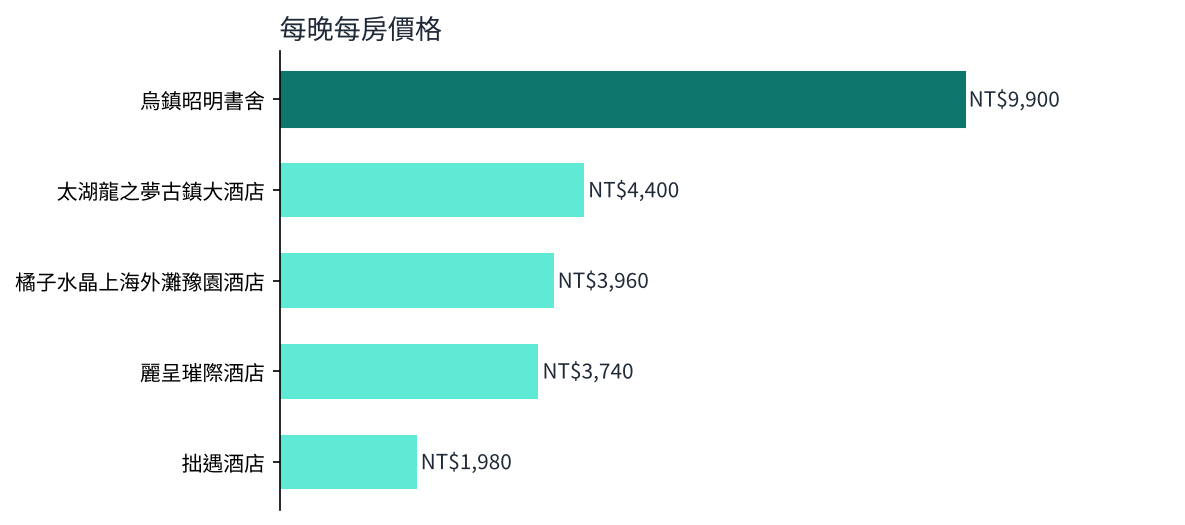

,日期,飯店,原始金額,晚數,每晚每房（人民幣）,每晚每房（台幣）
15,12/27,拙遇酒店,900,2,450.0,1980.0
1,12/24,麗呈璀際酒店,1700,2,850.0,3740.0
31,01/03,橘子水晶上海外灘豫園酒店,1800,2,900.0,3960.0
20,12/29,太湖龍之夢古鎮大酒店,3000,3,1000.0,4400.0
27,01/01,烏鎮昭明書舍,4500,2,2250.0,9900.0


In [8]:
hotels = items[items['類別'] == '住宿'][['日期', '飯店', '原始金額', '晚數']].copy()
hotels['晚數'] = hotels['晚數'].astype(int)
hotels['每晚每房（人民幣）'] = hotels['原始金額'] / hotels['晚數']
hotels['每晚每房（台幣）'] = (hotels['每晚每房（人民幣）'] * RMB_TO_TWD).round()
h = hotels.sort_values('每晚每房（台幣）')
fig, ax = plt.subplots(figsize=(8, 3.6), dpi=150)
bars = ax.barh(h['飯店'], h['每晚每房（台幣）'], color='#5eead4', height=0.6)
bars[-1].set_color(ACCENT)
for b, v in zip(bars, h['每晚每房（台幣）']):
    ax.text(v + 60, b.get_y() + b.get_height() / 2, f'NT${v:,.0f}', va='center', fontsize=10, color=INK)
ax.set_title('每晚每房價格', loc='left', fontsize=13, color=INK)
ax.spines[['top', 'right', 'bottom']].set_visible(False); ax.xaxis.set_visible(False)
ax.set_xlim(0, h['每晚每房（台幣）'].max() * 1.3)
plt.tight_layout(); plt.savefig('outputs/3_住宿比較.png'); plt.show()
h

## 7. 資料品質檢查

分析前先檢查資料本身有沒有問題——實務上，**找出資料的不一致，往往比畫圖更有價值**。

In [9]:
issues = []
# (1) 每間飯店實際住幾晚：從「第一次出現的日期」算到「下一間飯店第一次出現的日期」
def to_date(md): return pd.to_datetime(('2026/' if md.startswith('12') else '2027/') + md)
first = raw[raw['飯店'].notna()].groupby('飯店')['日期'].first().map(to_date).sort_values()
ends = list(first.values[1:]) + [to_date('01/05')]          # 最後一間住到 01/05 退房
for (name, start), end in zip(first.items(), ends):
    real = int((pd.Timestamp(end) - start).days)
    paid = hotels.loc[hotels['飯店'] == name, '晚數']
    if len(paid) and int(paid.iloc[0]) != real:
        issues.append(f"【住宿晚數】{name}：價錢寫 {int(paid.iloc[0])} 晚，但行程是 {start:%m/%d} 入住、{pd.Timestamp(end):%m/%d} 退房，共 {real} 晚 → 預算可能少算 {real - int(paid.iloc[0])} 晚")
# (2) 「平均一晚」與總價是否一致
for _, r in priced[priced['價錢'].astype(str).str.startswith('平均')].iterrows():
    s = str(r['價錢'])
    if '/人' in s and '/2人' not in s:
        issues.append(f"【單位不一致】{r['飯店']}：寫成「{s}」，但總價是以 2 人計，應為「/2人」")
# (3) 有備案價格
for s in priced['價錢'].astype(str):
    if '(' in s or '（' in s:
        issues.append(f"【備案價格】「{s}」括號內是備案，本分析取第一個價格")
for i in dict.fromkeys(issues): print('•', i)

• 【住宿晚數】麗呈璀際酒店：價錢寫 2 晚，但行程是 12/24 入住、12/27 退房，共 3 晚 → 預算可能少算 1 晚
• 【單位不一致】烏鎮昭明書舍：寫成「平均一晚2250/人」，但總價是以 2 人計，應為「/2人」
• 【備案價格】「門票300/2人(200/2人)」括號內是備案，本分析取第一個價格


## 8. 結論

- 每人總花費、各類別占比、最貴的一天，見上方結果（數字會隨匯率設定更新）。
- **機票與住宿**是主要支出，想省錢應優先比價這兩項；門票與交通相對小。
- 資料品質檢查發現：**上海第一間飯店價錢只寫 2 晚，但實際要住 3 晚**（12/24～12/27），預算少算一晚；另有單位寫法不一致。出發前應向飯店確認，避免預算低估。

**限制**：餐飲是依美食筆記的人均價格估算，未含每天的飲料與伴手禮；匯率為假設值；金額以 2 人同行計算。